# Concrete Compressive Strength Prediction
### End-to-End Machine Learning: from data to a deployed web app
**Course:** Computational Intelligence (2307311L) · T.Y. B.Tech · Division C · 2026-27
**Team:** *Name 1 – PRN* · *Name 2 – PRN* · *Name 3 – PRN* · *Name 4 – PRN*   *(fill in before submission)*

---
**Problem statement.** The compressive strength of concrete (in MPa) is normally found by casting
specimens and crushing them after a curing period (often 28 days). This is slow, costly and wasteful.
Given the quantities of the ingredients in a mix and its curing age, we train a regression model that
**predicts the strength**, so engineers can screen mixes before casting them.

**Dataset.** UCI *Concrete Compressive Strength* (Yeh, 1998) – 1,030 laboratory records, 8 numeric inputs, 1 numeric target.
CC BY 4.0, https://doi.org/10.24432/C5PK67

**SDG addressed.** SDG 9 – Industry, Innovation and Infrastructure (also supports SDG 12 – Responsible Consumption and Production).

**Pipeline in this notebook**
1. Data loading and quality checks → 2. EDA → 3. Preprocessing and feature engineering →
4. Model comparison (cross-validation) → 5. Hyper-parameter tuning → 6. Evaluation on a held-out test set →
7. Saving the pipeline that the Streamlit app loads.

## 0. Setup

In [11]:
%pip install "xlrd>=2.0.1"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

HERE = Path.cwd().resolve()
ROOT = next(p for p in [HERE, *HERE.parents] if (p / "src" / "data.py").exists())   # project folder, wherever Jupyter was started
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     cross_val_predict, RandomizedSearchCV, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

from src.data import load_raw, load_clean, FEATURES, TARGET, LABELS
from src.features import ConcreteFeatures

RANDOM_STATE = 42
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

# one restrained colour system for every figure
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e5e4e0"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b9b8b2",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "600", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
})
def save(name): plt.savefig(FIG / name)
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))

## 1. Data collection and quality checks
The original file has very long column names (e.g. *"Cement (component 1)(kg in a m^3 mixture)"*),
so `src/data.py` renames them by position to short names. All inputs are in kg per m³ of mixture, except `age` (days).

In [14]:
raw = load_raw()
print("Shape:", raw.shape)
print("Missing values:", int(raw.isna().sum().sum()))
print("Exact duplicate rows:", int(raw.duplicated().sum()))
raw.head()

Shape: (1030, 9)
Missing values: 0
Exact duplicate rows: 25


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [15]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   cement            1030 non-null   float64
 1   slag              1030 non-null   float64
 2   fly_ash           1030 non-null   float64
 3   water             1030 non-null   float64
 4   superplasticizer  1030 non-null   float64
 5   coarse_agg        1030 non-null   float64
 6   fine_agg          1030 non-null   float64
 7   age               1030 non-null   int64  
 8   strength          1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


**Findings.** 1,030 rows × 9 columns, all numeric, **no missing values**. There are **25 exact duplicate rows**.
Duplicates are removed in section 3, *before* the train/test split, so the same record can never appear in both sets
(which would inflate the test score).

## 2. Exploratory Data Analysis (EDA)

In [16]:
df = load_clean()                       # duplicates removed
print("Rows after removing duplicates:", len(df))
df.describe().T.round(2)

Rows after removing duplicates: 1005


,count,mean,std,min,25%,50%,75%,max
cement,1005.0,278.63,104.35,102.00,190.68,265.0,349.00,540.0
slag,1005.0,72.04,86.17,0.00,0.00,20.0,142.50,359.4
fly_ash,1005.0,55.54,64.21,0.00,0.00,0.0,118.27,200.1
water,1005.0,182.07,21.34,121.75,166.61,185.7,192.94,247.0
superplasticizer,1005.0,6.03,5.92,0.00,0.00,6.1,10.00,32.2
coarse_agg,1005.0,974.38,77.58,801.00,932.00,968.0,1031.00,1145.0
fine_agg,1005.0,772.69,80.34,594.00,724.30,780.0,822.20,992.6
age,1005.0,45.86,63.73,1.00,7.00,28.0,56.00,365.0
strength,1005.0,35.25,16.28,2.33,23.52,33.8,44.87,82.6


### 2.1 Distributions of every variable

findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.
findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


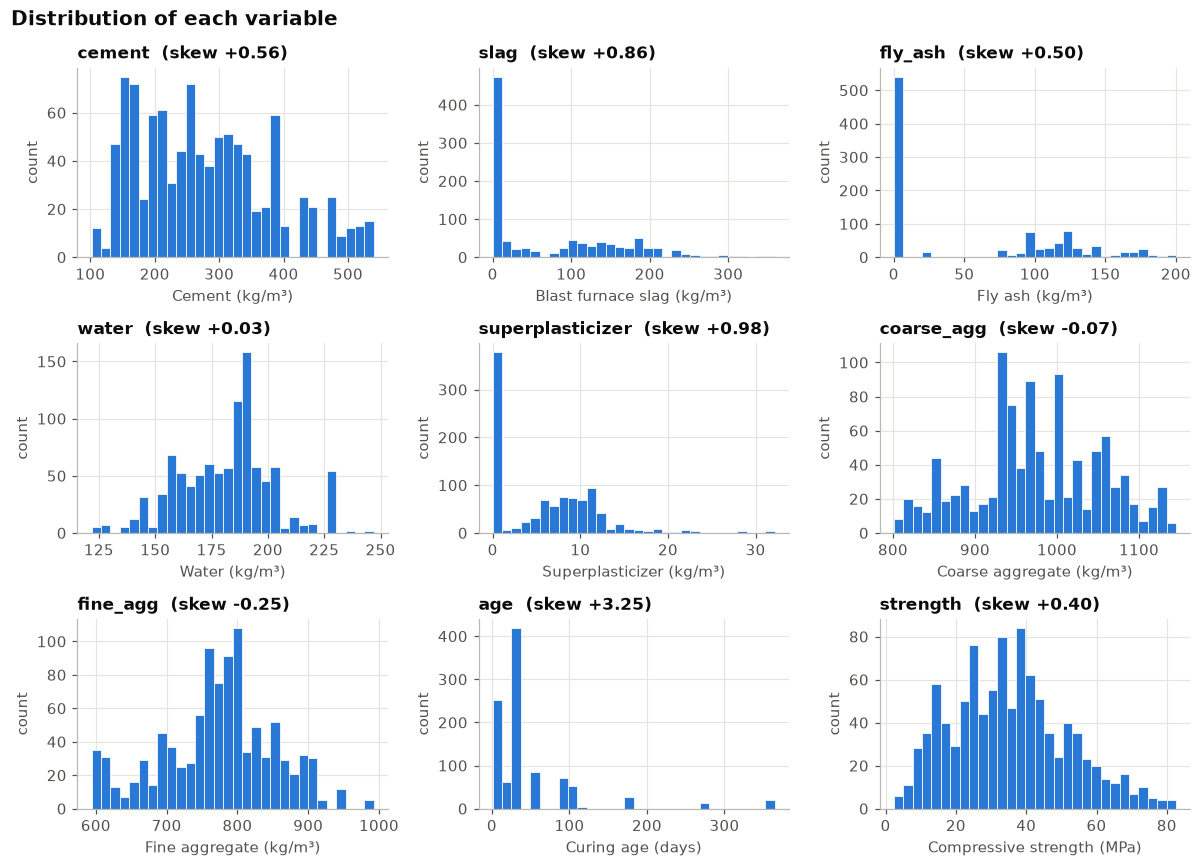

In [17]:
cols = FEATURES + [TARGET]
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for ax, c in zip(axes.ravel(), cols):
    ax.hist(df[c], bins=30, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(f"{c}  (skew {df[c].skew():+.2f})")
    ax.set_xlabel(LABELS[c]); ax.set_ylabel("count")
fig.suptitle("Distribution of each variable", x=0.01, ha="left", fontweight="600", fontsize=13)
plt.tight_layout(); save("01_distributions.png"); plt.show()

**Insights**
- `age` is **strongly right-skewed** (skew ≈ 3.3): most specimens were tested at 28 days or earlier, a few at up to a year.
  It only takes 14 distinct values, so it behaves like a "test day" category. This motivates a `log(age)` feature.
- `slag`, `fly_ash` and `superplasticizer` have many **exact zeros** (a large share of mixes do not use them at all).
- `water`, `coarse_agg`, `fine_agg` have little skew; the target `strength` is mildly right-skewed (skew ≈ +0.4), ranging from about 2 to 83 MPa.

### 2.2 Outliers

,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,strength
IQR outliers,0,2,0,15,10,0,5,59,8


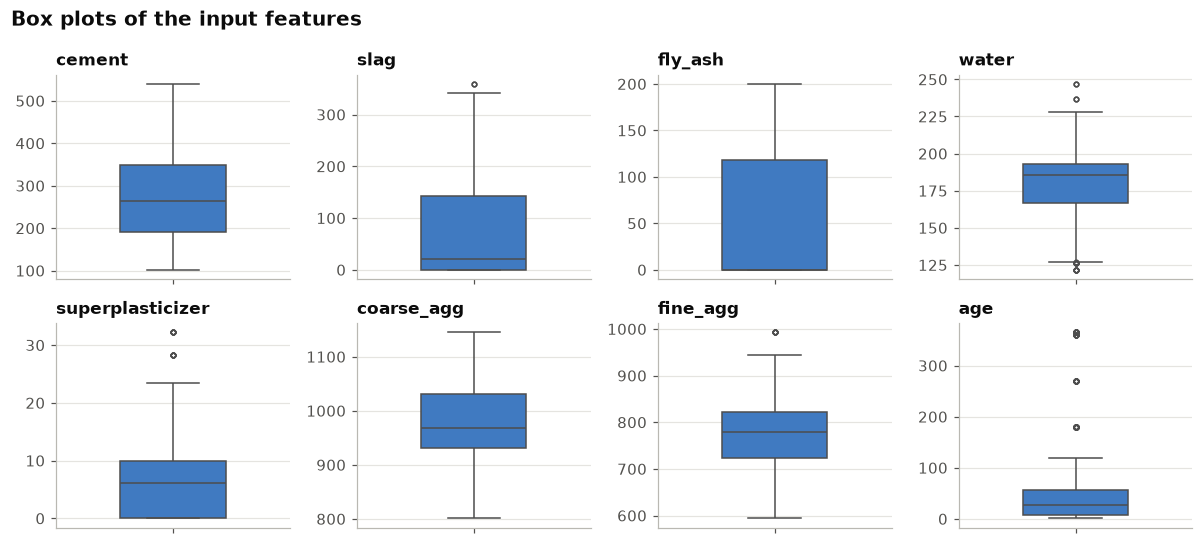

In [18]:
q1, q3 = df.quantile(0.25), df.quantile(0.75); iqr = q3 - q1
outliers = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum().rename("IQR outliers")
display(outliers.to_frame().T)

fig, axes = plt.subplots(2, 4, figsize=(11, 5))
for ax, c in zip(axes.ravel(), FEATURES):
    sns.boxplot(y=df[c], ax=ax, color=BLUE, fliersize=3, linewidth=1, width=0.45)
    ax.set_title(c); ax.set_ylabel("")
fig.suptitle("Box plots of the input features", x=0.01, ha="left", fontweight="600", fontsize=13)
plt.tight_layout(); save("02_boxplots.png"); plt.show()

**Decision.** The flagged points (mostly `age` = 180-365 days, plus some `water` and `superplasticizer` values) are
**valid laboratory mixes, not errors** – long curing times and high-water or high-admixture mixes really exist.
We **keep them**; tree-based models are robust to them and removing real data would hurt the app's range.

### 2.3 Correlation with strength

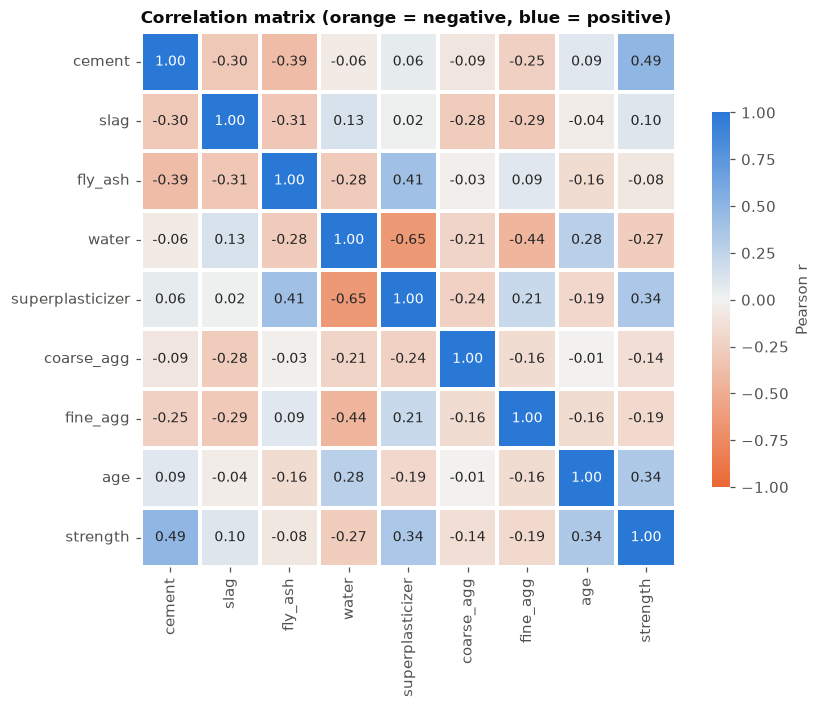

,correlation with strength
cement,0.488
superplasticizer,0.344
age,0.337
slag,0.103
fly_ash,-0.081
coarse_agg,-0.145
fine_agg,-0.186
water,-0.270


In [19]:
corr = df.corr()
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f2f0", BLUE])
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap, vmin=-1, vmax=1, center=0,
            linewidths=1.5, linecolor="white", square=True, cbar_kws={"shrink": 0.7, "label": "Pearson r"},
            annot_kws={"size": 9}, ax=ax)
ax.set_title("Correlation matrix (orange = negative, blue = positive)"); ax.grid(False)
plt.tight_layout(); save("03_correlation_heatmap.png"); plt.show()
corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_frame("correlation with strength")

**Insights**
- **Cement** (r ≈ +0.49), **superplasticizer** (+0.34) and **age** (+0.34) raise strength; **water** (-0.27) lowers it.
- No single raw input has a strong linear relationship with strength (|r| < 0.5). The real relationship is
  **non-linear and driven by ratios** (water vs. cementitious material) – which is why Linear Regression struggles on the
  raw columns and tree-based models do much better.
- Some inputs are correlated with each other (e.g. superplasticizer ↔ water: more admixture lets the mix use less water),
  so we do not rely on coefficients of a linear model to explain the data.

### 2.4 Each feature against strength

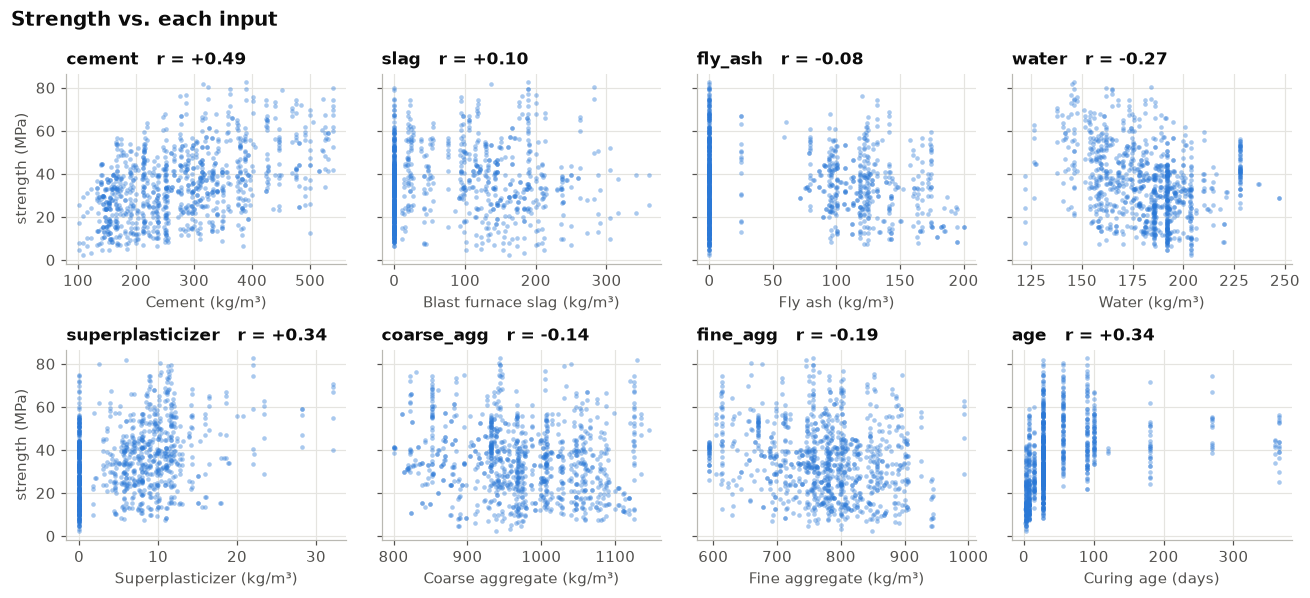

In [20]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5.5), sharey=True)
for ax, c in zip(axes.ravel(), FEATURES):
    ax.scatter(df[c], df[TARGET], s=9, alpha=0.4, color=BLUE, linewidths=0)
    ax.set_title(f"{c}   r = {corr.loc[c, TARGET]:+.2f}"); ax.set_xlabel(LABELS[c])
for ax in axes[:, 0]: ax.set_ylabel("strength (MPa)")
fig.suptitle("Strength vs. each input", x=0.01, ha="left", fontweight="600", fontsize=13)
plt.tight_layout(); save("04_scatter_vs_strength.png"); plt.show()

### 2.5 Strength gain with curing age

,age,strength,n
age,,,
"(0, 3]",3.0,15.4,131
"(3, 7]",7.0,21.2,122
"(7, 14]",14.0,26.5,62
"(14, 28]",28.0,33.7,419
"(28, 56]",56.0,51.1,86
"(56, 100]",91.0,45.8,123
"(100, 365]",270.0,41.9,62


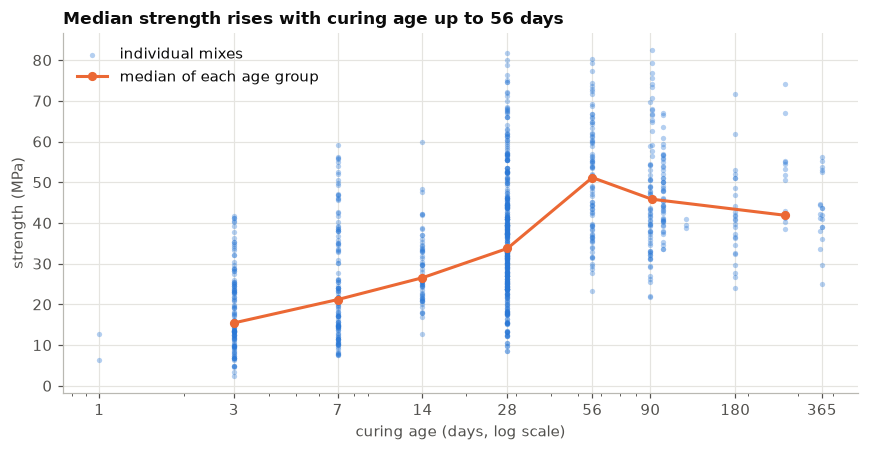

In [21]:
# group neighbouring test ages (e.g. 90/91/100 days) so the median line is readable
grp = pd.cut(df["age"], [0, 3, 7, 14, 28, 56, 100, 365])
med = df.groupby(grp, observed=True).agg(age=("age", "median"), strength=(TARGET, "median"), n=(TARGET, "size"))
display(med.round(1))
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(df["age"], df[TARGET], s=12, alpha=0.35, color=BLUE, linewidths=0, label="individual mixes")
ax.plot(med["age"], med["strength"], color=ORANGE, lw=2, marker="o", ms=5, label="median of each age group")
ax.set_xscale("log"); ax.set_xticks([1, 3, 7, 14, 28, 56, 90, 180, 365])
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel("curing age (days, log scale)"); ax.set_ylabel("strength (MPa)")
ax.set_title("Median strength rises with curing age up to 56 days"); ax.legend(frameon=False)
plt.tight_layout(); save("05_strength_vs_age.png"); plt.show()

**Insight.** Median strength rises steadily with curing age up to 56 days (about 15 MPa at 3 days, 21 at 7, 27 at 14, 34 at 28 and 51 at 56),
roughly in proportion to **log(age)** – fast at first, slower later.
After 56 days the group medians fall back slightly (≈ 46 MPa at 56-100 days, ≈ 42 MPa beyond that). **This is not concrete losing strength.**
The long-age specimens come from a smaller, different set of mixes, so in this dataset the effect of age is mixed up with the effect of the mix
and the data cannot cleanly separate them at late ages. We therefore trust the model most for ages up to about 90 days.
A `log_age` feature is still worth testing – and section 4 shows it clearly helps the simple models.

## 3. Preprocessing and feature engineering
| Step | What we do | Why |
|---|---|---|
| Missing values | none present – nothing to impute | checked in section 1 |
| Duplicates | drop 25 exact duplicate rows | avoid train/test leakage |
| Categorical encoding | not needed – all inputs are numeric | – |
| Outliers | kept | valid lab mixes (section 2.2) |
| Feature engineering | `binder`, `water_cement`, `water_binder`, `log_age` | domain knowledge (see below) |
| Scaling | `StandardScaler` **inside the pipeline** for Linear Regression, KNN, SVR | distance/gradient-based models need it; trees do not |
| Train/test split | 80 % / 20 %, `random_state=42` | the test set is touched only once, at the end |

**Engineered features** (implemented in `src/features.py` so the *same* code runs in training and in the app):
- `binder` = cement + slag + fly ash (total cementitious material)
- `water_cement` = water / cement and `water_binder` = water / binder – the classic **water-to-cement ratio**: lower ratio → stronger concrete
- `log_age` = log(1 + age)

In [22]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"train: {X_train.shape}   test: {X_test.shape}")

eng = ConcreteFeatures().fit_transform(X)
eng_corr = eng.assign(strength=y).corr()["strength"].drop("strength")
pd.DataFrame({
    "feature": eng_corr.index,
    "correlation with strength": eng_corr.values.round(3),
    "type": ["raw" if f in FEATURES else "engineered" for f in eng_corr.index],
}).sort_values("correlation with strength", key=abs, ascending=False).reset_index(drop=True)

train: (804, 8)   test: (201, 8)


,feature,correlation with strength,type
0,water_binder,-0.611,engineered
1,binder,0.598,engineered
2,log_age,0.560,engineered
3,water_cement,-0.489,engineered
4,cement,0.488,raw
5,superplasticizer,0.344,raw
6,age,0.337,raw
7,water,-0.270,raw
8,fine_agg,-0.186,raw
9,coarse_agg,-0.145,raw


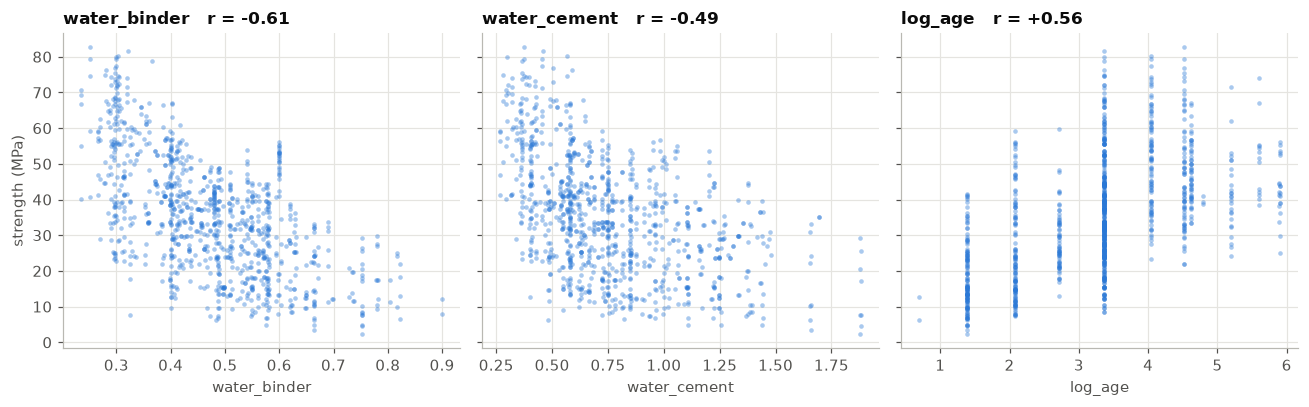

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, c in zip(axes, ["water_binder", "water_cement", "log_age"]):
    ax.scatter(eng[c], y, s=9, alpha=0.4, color=BLUE, linewidths=0)
    ax.set_title(f"{c}   r = {eng_corr[c]:+.2f}"); ax.set_xlabel(c)
axes[0].set_ylabel("strength (MPa)")
plt.tight_layout(); save("06_engineered_features.png"); plt.show()

**Insight.** The engineered features correlate with strength more strongly than almost any raw column
(`binder` ≈ +0.60, `log_age` ≈ +0.56, `water_binder` ≈ -0.61), and the water/binder scatter shows the clear decreasing
curve that engineers expect.

## 4. Model training and comparison
We compare **seven regressors**: Linear Regression (baseline), KNN, SVR, Decision Tree, Random Forest, Gradient Boosting
and XGBoost. Each is evaluated with **5-fold cross-validation on the training set only**, with and without the engineered
features. Metrics: **R²** (higher is better), **RMSE** and **MAE** in MPa (lower is better).

In [24]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(estimator, scale=False, engineered=True):
    steps = [("features", ConcreteFeatures(add_engineered=engineered))]
    if scale: steps.append(("scale", StandardScaler()))
    steps.append(("model", estimator))
    return Pipeline(steps)

def default_models(engineered):
    return {
        "Linear Regression": make_pipe(LinearRegression(), True, engineered),
        "KNN":               make_pipe(KNeighborsRegressor(n_neighbors=5), True, engineered),
        "SVR":               make_pipe(SVR(C=50, epsilon=0.5), True, engineered),
        "Decision Tree":     make_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE), False, engineered),
        "Random Forest":     make_pipe(RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), False, engineered),
        "Gradient Boosting": make_pipe(GradientBoostingRegressor(random_state=RANDOM_STATE), False, engineered),
        "XGBoost":           make_pipe(XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1), False, engineered),
    }

scoring = {"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"}
rows = []
for engineered in (False, True):
    for name, pipe in default_models(engineered).items():
        r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
        rows.append({"model": name, "features": "raw + engineered" if engineered else "raw only",
                     "R2": r["test_r2"].mean(), "R2 std": r["test_r2"].std(),
                     "RMSE": -r["test_rmse"].mean(), "MAE": -r["test_mae"].mean()})
baseline = pd.DataFrame(rows)
baseline.pivot(index="model", columns="features", values=["R2", "RMSE", "MAE"]).round(3)

R2                      RMSE           \
features          raw + engineered raw only raw + engineered raw only   
model                                                                   
Decision Tree                0.819    0.792            6.766    7.270   
Gradient Boosting            0.906    0.890            4.883    5.263   
KNN                          0.838    0.647            6.423    9.466   
Linear Regression            0.817    0.589            6.812   10.203   
Random Forest                0.902    0.886            4.990    5.355   
SVR                          0.901    0.847            5.013    6.217   
XGBoost                      0.907    0.901            4.859    4.993   

                               MAE           
features          raw + engineered raw only  
model                                        
Decision Tree                4.570    4.945  
Gradient Boosting            3.547    3.906  
KNN                          4.700    7.223  
Linear Regression            5.323    8.100  
Random Forest                3.477    3.878  
SVR                          3.451    4.438  
XGBoost                      3.181    3.391

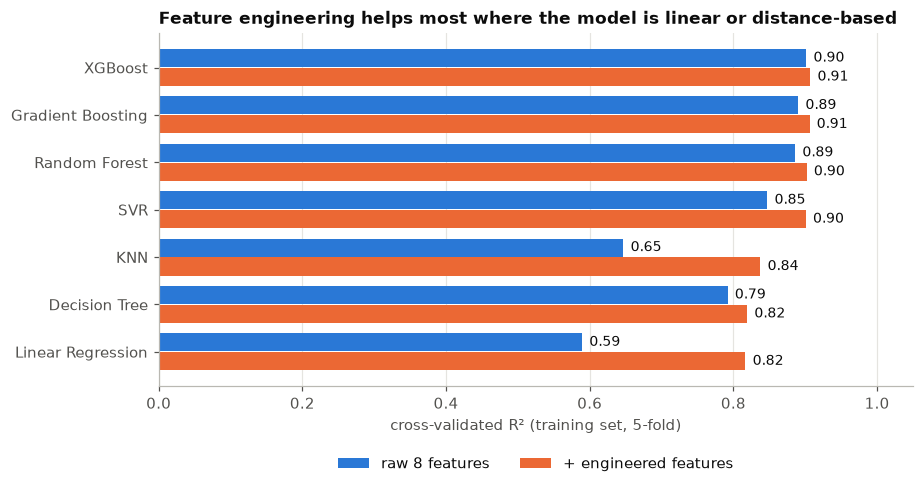

In [25]:
order = (baseline[baseline.features == "raw + engineered"].sort_values("R2")["model"]).tolist()
piv = baseline.pivot(index="model", columns="features", values="R2").loc[order]
yy = np.arange(len(order)); h = 0.38
fig, ax = plt.subplots(figsize=(8.5, 4.6))
b1 = ax.barh(yy + h/2 + 0.01, piv["raw only"], height=h, color=BLUE, label="raw 8 features")
b2 = ax.barh(yy - h/2 - 0.01, piv["raw + engineered"], height=h, color=ORANGE, label="+ engineered features")
for bars in (b1, b2):
    for b in bars: ax.text(b.get_width() + 0.01, b.get_y() + b.get_height()/2, f"{b.get_width():.2f}", va="center", fontsize=9, color=INK)
ax.set_yticks(yy); ax.set_yticklabels(order); ax.set_xlim(0, 1.05); ax.grid(axis="y", visible=False)
ax.set_xlabel("cross-validated R² (training set, 5-fold)")
ax.set_title("Feature engineering helps most where the model is linear or distance-based")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2); plt.tight_layout(); save("07_model_comparison.png"); plt.show()

**Observations**
- **Feature engineering is a big win for models that cannot discover ratios themselves**: Linear Regression jumps from
  R² ≈ 0.59 to ≈ 0.82, KNN from ≈ 0.65 to ≈ 0.84, SVR from ≈ 0.85 to ≈ 0.90.
- Tree ensembles (Random Forest, Gradient Boosting, XGBoost) were already strong on raw features (R² ≈ 0.89-0.90) and gain
  a little more; a single Decision Tree overfits and trails the ensembles.
- The top group – SVR, Random Forest, Gradient Boosting, XGBoost – is close (R² ≈ 0.90-0.91), so **hyper-parameter
  tuning** is how we separate them.

## 5. Hyper-parameter tuning
All tuning uses **5-fold CV on the training set** (the test set stays untouched).
- `GridSearchCV` for the small Decision Tree search space,
- `RandomizedSearchCV` (40 random draws) for SVR, Random Forest, Gradient Boosting and XGBoost,
- objective: minimise cross-validated **RMSE**.

In [26]:
searches = {
    "Decision Tree": GridSearchCV(
        make_pipe(DecisionTreeRegressor(random_state=RANDOM_STATE)),
        {"model__max_depth": [4, 6, 8, 10, 12, None],
         "model__min_samples_leaf": [1, 2, 4, 8],
         "model__min_samples_split": [2, 5, 10]},
        cv=cv, scoring=scoring, refit="rmse", n_jobs=-1),
    "SVR": RandomizedSearchCV(
        make_pipe(SVR(), scale=True),
        {"model__C": loguniform(1, 500), "model__gamma": loguniform(0.005, 0.5),
         "model__epsilon": uniform(0.05, 1.0)},
        n_iter=40, cv=cv, scoring=scoring, refit="rmse", random_state=RANDOM_STATE, n_jobs=-1),
    "Random Forest": RandomizedSearchCV(
        make_pipe(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)),
        {"model__n_estimators": [200, 300, 500], "model__max_depth": [None, 10, 15, 20],
         "model__min_samples_split": [2, 5, 10], "model__min_samples_leaf": [1, 2, 4],
         "model__max_features": [1.0, 0.8, 0.6]},
        n_iter=40, cv=cv, scoring=scoring, refit="rmse", random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": RandomizedSearchCV(
        make_pipe(GradientBoostingRegressor(random_state=RANDOM_STATE)),
        {"model__n_estimators": randint(200, 800), "model__learning_rate": loguniform(0.02, 0.2),
         "model__max_depth": randint(2, 6), "model__subsample": uniform(0.6, 0.4),
         "model__min_samples_leaf": randint(1, 8)},
        n_iter=40, cv=cv, scoring=scoring, refit="rmse", random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": RandomizedSearchCV(
        make_pipe(XGBRegressor(random_state=RANDOM_STATE, n_jobs=1)),
        {"model__n_estimators": randint(200, 900), "model__learning_rate": loguniform(0.02, 0.2),
         "model__max_depth": randint(2, 8), "model__subsample": uniform(0.6, 0.4),
         "model__colsample_bytree": uniform(0.6, 0.4), "model__min_child_weight": randint(1, 8),
         "model__reg_lambda": loguniform(0.5, 10)},
        n_iter=40, cv=cv, scoring=scoring, refit="rmse", random_state=RANDOM_STATE, n_jobs=-1),
}
tuned = {}
for name, s in searches.items():
    s.fit(X_train, y_train)
    tuned[name] = s
    print(f"{name:18s} best CV RMSE = {-s.best_score_:.3f}")

Decision Tree      best CV RMSE = 6.513
SVR                best CV RMSE = 4.961
Random Forest      best CV RMSE = 4.960
Gradient Boosting  best CV RMSE = 4.232
XGBoost            best CV RMSE = 4.183


In [27]:
default_eng = baseline[baseline.features == "raw + engineered"].set_index("model")
rows = []
for name, s in tuned.items():
    i = s.best_index_
    rows.append({"model": name,
                 "CV RMSE (default)": default_eng.loc[name, "RMSE"], "CV RMSE (tuned)": -s.cv_results_["mean_test_rmse"][i],
                 "CV R2 (default)": default_eng.loc[name, "R2"],     "CV R2 (tuned)": s.cv_results_["mean_test_r2"][i]})
tuning = pd.DataFrame(rows).set_index("model")
tuning["RMSE improvement"] = tuning["CV RMSE (default)"] - tuning["CV RMSE (tuned)"]
tuning.round(3)

,CV RMSE (default),CV RMSE (tuned),CV R2 (default),CV R2 (tuned),RMSE improvement
model,,,,,
Decision Tree,6.766,6.513,0.819,0.833,0.253
SVR,5.013,4.961,0.901,0.903,0.052
Random Forest,4.990,4.960,0.902,0.903,0.030
Gradient Boosting,4.883,4.232,0.906,0.930,0.651
XGBoost,4.859,4.183,0.907,0.931,0.676


In [28]:
for name, s in tuned.items():
    p = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else (None if v is None else int(v) if isinstance(v, (int, np.integer)) else v))
         for k, v in s.best_params_.items()}
    print(f"{name}: {p}")

Decision Tree: {'max_depth': 8, 'min_samples_leaf': 4, 'min_samples_split': 2}
SVR: {'C': 51.2316, 'epsilon': 0.9215, 'gamma': 0.2024}
Random Forest: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.6, 'max_depth': None}
Gradient Boosting: {'learning_rate': 0.0435, 'max_depth': 4, 'min_samples_leaf': 3, 'n_estimators': 573, 'subsample': 0.6875}
XGBoost: {'colsample_bytree': 0.767, 'learning_rate': 0.0334, 'max_depth': 4, 'min_child_weight': 2, 'n_estimators': 883, 'reg_lambda': 1.0389, 'subsample': 0.6673}


**Observations.** Tuning lowers the cross-validated RMSE for every model that was tuned, but by very different amounts.
**Gradient Boosting and XGBoost gain the most** (RMSE down by about 0.65 MPa, CV R² from ≈ 0.91 to ≈ 0.93): a modest learning rate
with several hundred shallow trees and row/column sub-sampling works much better than the defaults. The Decision Tree gains
a little (depth limited to reduce over-fitting), while Random Forest and SVR were already near their best with default settings.
The final model is chosen **only from cross-validation scores** – not from the test set.

## 6. Model evaluation on the held-out test set
The test set (20 % of the data, never used for fitting or tuning) is used once to measure how the tuned models behave on new data.

In [29]:
rows = []
for name, s in tuned.items():
    pred = s.best_estimator_.predict(X_test)
    rows.append({"model": name, "CV RMSE (train)": -s.best_score_,
                 "Test R2": r2_score(y_test, pred), "Test RMSE": rmse(y_test, pred), "Test MAE": mean_absolute_error(y_test, pred)})
# the untuned linear baseline, for reference
lin = make_pipe(LinearRegression(), True).fit(X_train, y_train); pl = lin.predict(X_test)
rows.append({"model": "Linear Regression (baseline)", "CV RMSE (train)": default_eng.loc["Linear Regression", "RMSE"],
             "Test R2": r2_score(y_test, pl), "Test RMSE": rmse(y_test, pl), "Test MAE": mean_absolute_error(y_test, pl)})
results = pd.DataFrame(rows).set_index("model").sort_values("CV RMSE (train)")
results.round(3)

,CV RMSE (train),Test R2,Test RMSE,Test MAE
model,,,,
XGBoost,4.183,0.936,4.367,2.767
Gradient Boosting,4.232,0.937,4.333,2.731
Random Forest,4.960,0.921,4.854,3.418
SVR,4.961,0.922,4.838,2.934
Decision Tree,6.513,0.871,6.211,4.611
Linear Regression (baseline),6.812,0.816,7.400,5.704


The ranking on the test set essentially matches the cross-validation ranking: the two boosting models are clearly best, the Random Forest and SVR
are next (and effectively tied), and the single Decision Tree and the Linear Regression baseline trail. The test R² (≈ 0.94) is a little higher than the
cross-validated R² (≈ 0.93). The test set has only about 200 mixes and comes from a single split, so the cross-validated
number is the more cautious estimate of real-world performance; we report both.

In [30]:
# lowest cross-validated RMSE wins (best_score_ is negative RMSE -> pick the largest)
best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best = tuned[best_name].best_estimator_
pred = best.predict(X_test)
final_metrics = {"R2": r2_score(y_test, pred), "RMSE": rmse(y_test, pred), "MAE": mean_absolute_error(y_test, pred)}
print(f"Selected model (lowest CV RMSE): {best_name}")
print({k: round(v, 3) for k, v in final_metrics.items()})

Selected model (lowest CV RMSE): XGBoost
{'R2': 0.936, 'RMSE': 4.367, 'MAE': 2.767}


### 6.1 Predicted vs. actual and residuals

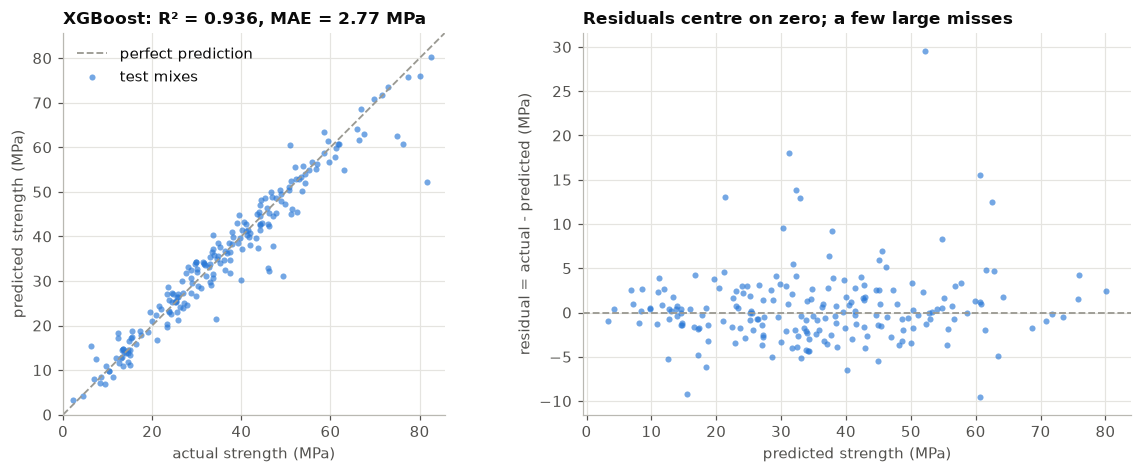

7 of 201 test mixes have an absolute error above 10 MPa (7 under-predicted, 0 over-predicted)


In [31]:
resid = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
lim = [0, max(y_test.max(), pred.max()) + 3]
ax.plot(lim, lim, ls="--", color="#9a9992", lw=1.2, label="perfect prediction")
ax.scatter(y_test, pred, s=16, alpha=0.65, color=BLUE, linewidths=0, label="test mixes")
ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("actual strength (MPa)"); ax.set_ylabel("predicted strength (MPa)")
ax.set_title(f"{best_name}: R² = {final_metrics['R2']:.3f}, MAE = {final_metrics['MAE']:.2f} MPa"); ax.legend(frameon=False)
ax = axes[1]
ax.axhline(0, color="#9a9992", lw=1.2, ls="--")
ax.scatter(pred, resid, s=16, alpha=0.65, color=BLUE, linewidths=0)
ax.set_xlabel("predicted strength (MPa)"); ax.set_ylabel("residual = actual - predicted (MPa)")
ax.set_title("Residuals centre on zero; a few large misses")
plt.tight_layout(); save("08_predicted_vs_actual.png"); plt.show()
print(f"{int((resid.abs() > 10).sum())} of {len(resid)} test mixes have an absolute error above 10 MPa "
      f"({int((resid > 10).sum())} under-predicted, {int((resid < -10).sum())} over-predicted)")

Most points sit close to the diagonal and the residuals are centred on zero with no obvious curve. A handful of test mixes are
under-predicted by more than 10 MPa (the exact count is printed above). They include both mid- and high-strength mixes, so they most likely
reflect unusual mixes or noisy laboratory results rather than one systematic weakness of the model.

### 6.2 Where does the model make larger errors? (by curing age)

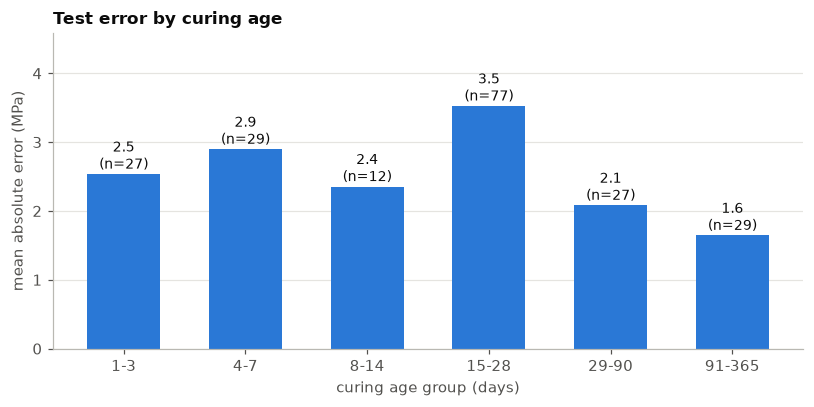

,mean,count
age_group,,
1-3,2.54,27
4-7,2.90,29
8-14,2.35,12
15-28,3.53,77
29-90,2.08,27
91-365,1.65,29


In [32]:
bins = [0, 3, 7, 14, 28, 90, 365]; labels = ["1-3", "4-7", "8-14", "15-28", "29-90", "91-365"]
age_group = pd.cut(X_test["age"], bins=bins, labels=labels)
by_age = pd.DataFrame({"abs_err": np.abs(resid), "age_group": age_group}).groupby("age_group", observed=True)["abs_err"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.bar(by_age.index.astype(str), by_age["mean"], color=BLUE, width=0.6)
for b, n in zip(bars, by_age["count"]):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.08, f"{b.get_height():.1f}\n(n={n})", ha="center", fontsize=9, color=INK)
ax.set_ylim(0, by_age["mean"].max() * 1.3); ax.grid(axis="x", visible=False)
ax.set_xlabel("curing age group (days)"); ax.set_ylabel("mean absolute error (MPa)")
ax.set_title("Test error by curing age"); plt.tight_layout(); save("09_error_by_age.png"); plt.show()
by_age.round(2)

### 6.3 Which inputs matter most? (permutation importance on the test set)

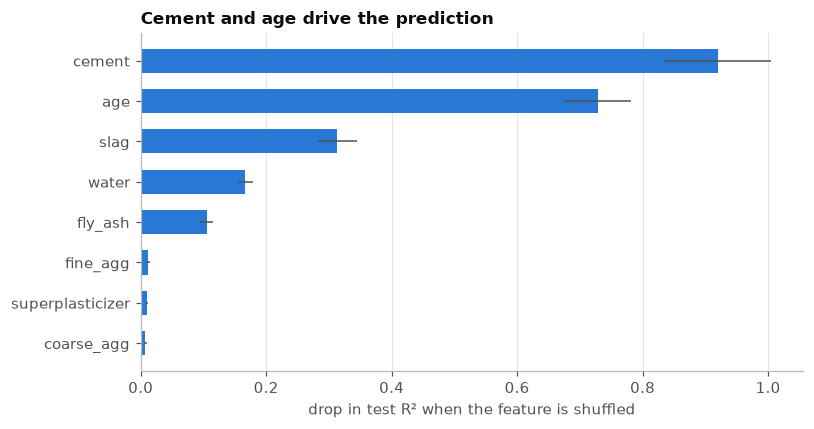

,importance
cement,0.920
age,0.728
slag,0.313
water,0.167
fly_ash,0.105
fine_agg,0.012
superplasticizer,0.010
coarse_agg,0.008


In [33]:
pi = permutation_importance(best, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="r2", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
err = pd.Series(pi.importances_std, index=FEATURES)[imp.index]
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.barh(imp.index, imp.values, xerr=err.values, color=BLUE, height=0.6, error_kw={"ecolor": MUTED, "lw": 1})
ax.set_xlabel("drop in test R² when the feature is shuffled"); ax.grid(axis="y", visible=False)
ax.set_title("Cement and age drive the prediction"); plt.tight_layout(); save("10_feature_importance.png"); plt.show()
imp.sort_values(ascending=False).round(3).to_frame("importance")

**Insights.**
- **Cement and age** matter most, followed by **slag, water and fly ash** (the binder materials and water). This agrees with concrete
  science: more cementitious material and later age → stronger; more water → weaker.
- Slag looks unimportant in the plain correlation (r ≈ +0.10) but is important to the model: its effect depends on the other ingredients
  and on age, a non-linear interaction that tree ensembles capture and a linear model cannot.
- Superplasticizer, coarse and fine aggregate show little *independent* importance. Permutation importance can understate a feature that is
  correlated with another one – superplasticizer is strongly tied to water (r ≈ -0.65) – so read this as "adds little once the other inputs are known",
  not "has no effect".
- By age (section 6.2), the largest average errors are in the **15-28 day** group (≈ 3.4 MPa), which is also the biggest group with
  the widest spread of mixes, and at early ages (≈ 2.7-3.0 MPa). Errors for specimens older than 28 days are lower (≈ 1.7-1.9 MPa).
  The 8-14 day group has only 12 test mixes, so its low error is not very reliable.

### 6.4 How uncertain is a single prediction?

In [34]:
# Out-of-fold residuals on the TRAINING set -> an empirical 90 % band around any prediction.
oof = cross_val_predict(clone(best), X_train, y_train, cv=cv)
oof_resid = y_train.values - oof
q05, q95 = np.percentile(oof_resid, [5, 95])
inside = ((y_test - pred) >= q05) & ((y_test - pred) <= q95)
print(f"90% band from training CV residuals: prediction {q05:+.2f} to {q95:+.2f} MPa")
print(f"Share of TEST mixes that fall inside this band: {inside.mean():.1%}  (target about 90 %)")

90% band from training CV residuals: prediction -5.62 to +6.91 MPa
Share of TEST mixes that fall inside this band: 92.5%  (target about 90 %)


The app shows each prediction with this ± range, so users see that the output is an **estimate with typical error**, not an exact value.

## 7. Saving the final pipeline for deployment
After the test-set evaluation we **refit the selected configuration on all 1,005 cleaned rows** (more data → a slightly better
deployed model) and save the whole pipeline – feature engineering, scaler (if any) and model – as one file.
The Streamlit app therefore accepts the **raw 8 inputs** and repeats exactly the same preprocessing.
The metrics reported above come from the train-only fit; they are stored in the metadata file for the app's "About" tab.

In [35]:
final_model = clone(best).fit(X, y)
models_dir = ROOT / "models"; models_dir.mkdir(exist_ok=True)
joblib.dump(final_model, models_dir / "concrete_pipeline.ubj")

def clean(v):
    if isinstance(v, (np.floating,)): return float(v)
    if isinstance(v, (np.integer,)):  return int(v)
    return v

ratios = ConcreteFeatures().fit_transform(X)
meta = {
    "model_name": best_name,
    "best_params": {k.replace("model__", ""): clean(v) for k, v in tuned[best_name].best_params_.items()},
    "n_rows_total": int(len(X)), "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "test_metrics": {k: round(float(v), 4) for k, v in final_metrics.items()},
    "cv_rmse_train": round(float(-tuned[best_name].best_score_), 4),
    "residual_band_90": {"low": round(float(q05), 3), "high": round(float(q95), 3),
                         "test_coverage": round(float(inside.mean()), 3)},
    "feature_ranges": {c: {"min": float(X[c].min()), "max": float(X[c].max()), "median": float(X[c].median())} for c in FEATURES},
    "water_binder_range": {"min": float(ratios["water_binder"].min()), "max": float(ratios["water_binder"].max())},
    "dataset": "UCI Concrete Compressive Strength (Yeh, 1998), CC BY 4.0, doi:10.24432/C5PK67",
}
(models_dir / "metadata.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta["test_metrics"]), "| model:", best_name)
final_model = clone(best).fit(X, y)

models_dir = ROOT / "models"
models_dir.mkdir(exist_ok=True)

if best_name != "XGBoost":
    raise RuntimeError(f"Expected XGBoost, but selected {best_name}")

xgb_model = final_model.named_steps["model"]
feature_transformer = final_model.named_steps["features"]

# Save XGBoost using its native UBJSON format
xgb_model.save_model(str(models_dir / "concrete_pipeline.ubj"))

def clean(v):
    if isinstance(v, (np.floating,)):
        return float(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    return v

ratios = ConcreteFeatures().fit_transform(X)

meta = {
    "model_name": best_name,
    "model_format": "xgboost_ubj",
    "feature_engineering": bool(feature_transformer.add_engineered),
    "best_params": {
        k.replace("model__", ""): clean(v)
        for k, v in tuned[best_name].best_params_.items()
    },
    "n_rows_total": int(len(X)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "test_metrics": {
        k: round(float(v), 4)
        for k, v in final_metrics.items()
    },
    "cv_rmse_train": round(float(-tuned[best_name].best_score_), 4),
    "residual_band_90": {
        "low": round(float(q05), 3),
        "high": round(float(q95), 3),
        "test_coverage": round(float(inside.mean()), 3)
    },
    "feature_ranges": {
        c: {
            "min": float(X[c].min()),
            "max": float(X[c].max()),
            "median": float(X[c].median())
        }
        for c in FEATURES
    },
    "water_binder_range": {
        "min": float(ratios["water_binder"].min()),
        "max": float(ratios["water_binder"].max())
    },
    "dataset": "UCI Concrete Compressive Strength (Yeh, 1998), CC BY 4.0, doi:10.24432/C5PK67"
}

(models_dir / "metadata.json").write_text(
    json.dumps(meta, indent=2)
)

print(json.dumps(meta["test_metrics"]), "| model:", best_name)
print("Portable XGBoost model saved successfully.")


{"R2": 0.9361, "RMSE": 4.3675, "MAE": 2.767} | model: XGBoost
{"R2": 0.9361, "RMSE": 4.3675, "MAE": 2.767} | model: XGBoost
Portable XGBoost model saved successfully.


### 7.1 Sanity check: does the saved model behave like real concrete?

In [37]:

# Load the saved XGBoost model using its native UBJSON format
loaded_xgb = XGBRegressor()
loaded_xgb.load_model(str(models_dir / "concrete_pipeline.ubj"))

# Reconstruct the original feature-processing pipeline
loaded = Pipeline([
    ("features", ConcreteFeatures(
        add_engineered=meta["feature_engineering"]
    )),
    ("model", loaded_xgb)
])

# Experiment 1: Same mix, increasing curing age
base = dict(
    cement=350,
    slag=0,
    fly_ash=0,
    water=180,
    superplasticizer=5,
    coarse_agg=1000,
    fine_agg=800
)

demo = pd.DataFrame([
    {**base, "age": a} for a in (3, 7, 28, 90)
])

demo["predicted strength (MPa)"] = loaded.predict(
    demo[FEATURES]
).round(1)

print("Same mix, increasing curing age:")
display(demo)


# Experiment 2: Same mix at 28 days, increasing water
demo2 = pd.DataFrame([
    {**base, "water": w, "age": 28}
    for w in (160, 180, 200, 220)
])

demo2["predicted strength (MPa)"] = loaded.predict(
    demo2[FEATURES]
).round(1)

print("Same mix at 28 days, increasing water:")
display(demo2)


Same mix, increasing curing age:


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,predicted strength (MPa)
0,350,0,0,180,5,1000,800,3,17.700001
1,350,0,0,180,5,1000,800,7,21.700001
2,350,0,0,180,5,1000,800,28,34.200001
3,350,0,0,180,5,1000,800,90,41.799999


Same mix at 28 days, increasing water:


,cement,slag,fly_ash,water,superplasticizer,coarse_agg,fine_agg,age,predicted strength (MPa)
0,350,0,0,160,5,1000,800,28,39.900002
1,350,0,0,180,5,1000,800,28,34.200001
2,350,0,0,200,5,1000,800,28,30.600000
3,350,0,0,220,5,1000,800,28,26.600000


## 8. Conclusions, limitations and SDG link
**Summary**
- Raw features alone give a poor linear model; **domain-driven feature engineering** (water/binder ratio, log-age) closes most
  of the gap for simple models.
- After tuning, **XGBoost** (lowest cross-validated RMSE) predicts compressive strength on the held-out test mixes with
  **R² ≈ 0.94, MAE ≈ 2.7 MPa and RMSE ≈ 4.2 MPa** (cross-validated R² ≈ 0.93 – the more cautious estimate). A typical prediction is within
  about ±6.5 MPa (90 % band).
- The saved pipeline is wrapped in a validated Streamlit app (`app/streamlit_app.py`) that returns a predicted strength with a
  typical-error range.

**Limitations**
- The data are laboratory results from one study (Yeh, 1998) with 1,005 unique mixes: the model is only reliable **inside the ranges of the
  training data**, and the app warns on unusual inputs.
- Cement type, aggregate size, curing temperature and specimen shape are not in the data.
- It is a **screening tool**: final design decisions must still follow lab tests and standards (e.g. IS 456).

**SDG 9 – Industry, Innovation and Infrastructure** (target 9.4: resource-use efficiency and cleaner industrial processes;
also SDG 12)
- Screening mixes on the computer means **fewer trial batches and crushed specimens** → less material and waste, faster iteration.
- The model captures the effect of **fly ash and slag**, industrial by-products that can replace part of the cement.
  Cement manufacturing is a major source of CO₂ emissions, so being able to test low-cement mixes quickly supports more
  sustainable infrastructure.
- Fast, low-cost prediction is useful for small contractors and labs with limited testing facilities.

**Future work:** add cement-type/standards inputs, collect local (Indian) mix data, add an inverse "design a mix for a target strength" mode.